# Exercise 2
Nico Reiterer - 5191 2112

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2.1. c)
Write a matlab or python program that computes the Newton coefficients and evaluates the
resulting polynomial at a vector of evaluation points using the Horner scheme. Input are the
vectors x, f (knots and data values) of length n+ 1.
Check your routines against the results of a) and b). Plot f and p3 on [0,4], and calculate the
error $||f−p3||{_∞,[0,4]}.$ by sampling using 1001 uniformly distributed evaluation points.

In [2]:
def newton_polynomial(j: int, x: np.ndarray, x_dash: float | np.ndarray) -> float | np.ndarray:
    """
        j: order of the polynomial
        x: knots x_i
        x_dash: evaluation point

        Returns:
            The newton polynomial w_j
    """

    x_dash = np.asarray(x_dash, dtype=float)
    return np.prod(x_dash[..., None] - x[:j], axis=-1)


def divided_differences(x: np.ndarray, y: np.ndarray) -> np.ndarray:
    """
        x: knots x_i
        y: values f(x_i)

        Returns:
            Newton coefficients c_j = f[x_0, ..., x_j]
    
    """
    # start of the row k = 0
    c = np.array(y, dtype=float)

    # k elem of [0, n-1] based on the number of knots.
    n = len(x) 
    # Essentially going along the columns and creating in first step f[x0, x1], f[x1, x2] ...
    # Then in next step taking these calculated ones to create f[x0, x1, x2] consisting for the
    # created f[x0, x1], f[x1, x2] >> f[x0, x1, x2] =  f[x1, x2] - f[x0, x1] / x2-x1
    for k in range(1, n):
        for i in range(n - 1, k - 1, -1):   # go backwards so c[i-1] is still the old value
            c[i] = (c[i] - c[i-1]) / (x[i] - x[i-k])
    return c


def horner_schema(c: np.ndarray, x: np.ndarray, x_dash: float | np.ndarray) -> float | np.ndarray:
    """
        c: Newton coefficients (from divided_differences)
        x: knots x_i
        x_dash: evaluation point(s), scalar or array

        Returns:
            p(x_dash) evaluated with the Horner-like scheme
    """
    x_dash = np.asarray(x_dash, dtype=float)
    y = np.full_like(x_dash, c[-1]) # just to be flexible for evaluation of multiple x_dashes at once
    for j in range(len(c) - 2, -1, -1):
        y = y * (x_dash - x[j]) + c[j]
    return y


Newton coefficients: [ 1.         -0.5         0.16666667 -0.03333333]
|f(3) - p3(3)| = 0.050000000000000044
||f - p3||_inf,[0,4] = 0.053771  (attained at x ≈ 3.244)


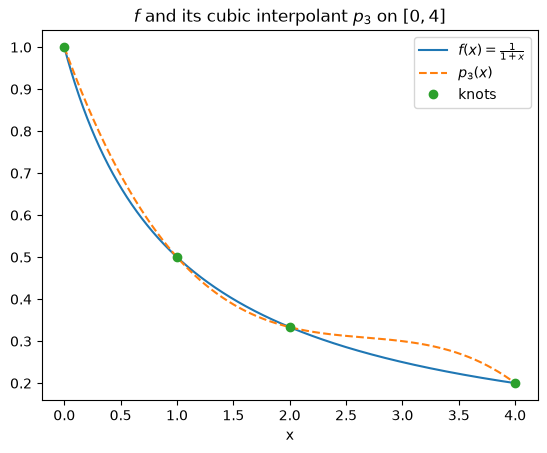

In [3]:
# Validating my results from the handwritten evaluation
x = np.array([0., 1, 2, 4])
f = lambda x: 1/(1+x)
c = divided_differences(x, f(x))

# a): c = [f[x0], f[x0,x1], f[x0,x1,x2], f[x0,...,x3]] = [1, -1/2, 1/6, -1/30]
print("Newton coefficients:", c)

# b): p3(3) = 0.3, |f(3) - p3(3)| = 0.05
print("|f(3) - p3(3)| =", abs(f(3) - horner_schema(c, x, 3)))

# Now the uniformly distributed values between 0 and 4
x_eval = np.linspace(0, 4, 1001)
f_eval = f(x_eval)
p3_eval = horner_schema(c, x, x_eval)

error = np.abs(f_eval - p3_eval)
print(f"||f - p3||_inf,[0,4] = {error.max():.6f}  (attained at x ≈ {x_eval[error.argmax()]:.3f})")

plt.plot(x_eval, f_eval, label=r"$f(x) = \frac{1}{1+x}$")
plt.plot(x_eval, p3_eval, "--", label=r"$p_3(x)$")
plt.plot(x, f(x), "o", label="knots")
plt.xlabel("x")
plt.legend()
plt.title(r"$f$ and its cubic interpolant $p_3$ on $[0, 4]$")
plt.show()

## 2.2 calculations

In [4]:
np.exp(1.2) - (1 + (np.exp(1) - 1) * 1.2 + 0.5 * (np.exp(1)**2 - 2 * np.exp(1) + 1)* 0.24)

np.float64(-0.09612036445581396)

In [5]:
# Showing the upper bound for vals in range (0, 2) for which the max(exp(range)) = exp(2)
x = 1.2
np.abs((x**3 - 3*x**2 + 2*x))/6 * np.exp(1.2) 

np.float64(0.10624374152756987)

In [6]:
print((6 + np.sqrt(12))/6, (6 - np.sqrt(12)/6))

w = lambda x: x**3 - 3*x**2 + 2*x
w((6 + np.sqrt(12))/6)

1.5773502691896255 5.422649730810374


np.float64(-0.3849001794597502)

In [7]:
w((6 + np.sqrt(12))/6) * np.exp(2) / 6

np.float64(-0.47400816975276155)

## 2.3 - Neville scheme

> "A prime application of this method is to compute derivatives of a function for which only function values are available."

In [ ]:
def N(f: np.ndarray, x: np.ndarray, x_dash: float) -> np.ndarray:
    """
    Algorithm 1 (Aitken-Neville Scheme) from p.5 of the script

        f: vector f ∈ Rn+
        x: knot vector x ∈ Rn+1
    
    """
    n = len(x)
    N = np.zeros((n, n)) # or rather np.full((n, n), np.nan) because zero could be a value ofc
    N[:,0] = f

    for m in range(1, n):
        for j in range(0, n - m):
            p_jm = (x_dash - x[j]) * N[j + 1, m - 1] - (x_dash - x[j+m]) * N[j, m - 1]
            p_jm /= (x[j+m] - x[j])
            N[j, m] =  p_jm
    
    return N

In [9]:
x = np.array([0, 1, 2, 4])
f = lambda x: 1/(1+x)
y = f(x)
x_dash = 3

test = N(y, x, x_dash)
test

array([[ 1.        , -0.5       ,  0.5       ,  0.3       ],
       [ 0.5       ,  0.16666667,  0.23333333,  0.        ],
       [ 0.33333333,  0.26666667,  0.        ,  0.        ],
       [ 0.2       ,  0.        ,  0.        ,  0.        ]])

In [10]:
def D_sim(f:callable, h: float | np.ndarray, x_0: float | np.ndarray) -> float | np.ndarray:
    return (f(x_0 + h) - f(x_0 - h))/ (2 * h)

In [11]:
f_x = lambda x: np.tan(x)
x_0 = np.pi / 4
n_max = 10
i = np.linspace(0, n_max, n_max + 1)
h = 2 ** (- i)

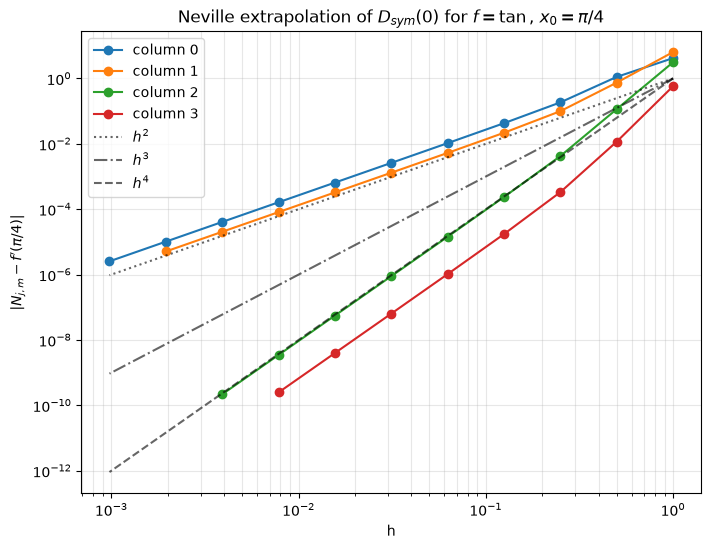

In [12]:
# knots: h_i, data: D_sym(h_i); extrapolate the interpolating polynomial to h = 0
D = D_sim(f_x, h, x_0)
N_scheme = N(D, h, 0)

exact = 2  # f'(pi/4) = 1/cos^2(pi/4)

plt.figure(figsize=(8, 6))
for m in range(4):
    # column m has n_max + 1 - m entries; N[j, m] uses the knots h_j, ..., h_{j+m}
    h_m = h[:n_max + 1 - m]
    err = np.abs(N_scheme[:n_max + 1 - m, m] - exact)
    plt.loglog(h_m, err, "o-", label=f"column {m}")

for p, style in zip([2, 3, 4], [":", "-.", "--"]):
    plt.loglog(h, h**p, "k" + style, alpha=0.6, label=f"$h^{p}$")

plt.xlabel("h")
plt.ylabel(r"$|N_{j,m} - f'(\pi/4)|$")
plt.title(r"Neville extrapolation of $D_{sym}(0)$ for $f = \tan$, $x_0 = \pi/4$")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()


**Observed convergence rates:**

| column | rate |
|---|---|
| 0 ($D_{sym}(h)$ itself) | $\mathcal{O}(h^2)$ |
| 1 | $\mathcal{O}(h^2)$ |
| 2 | $\mathcal{O}(h^4)$ |
| 3 | $\mathcal{O}(h^4)$ |

First of all, the smaller h the smaller the error which makes sense as we are getting closer to the actual differential and its value at pi/4.

Secondly, the order only increases every second column. The reason is the Taylor expansion of the symmetric difference quotient, which contains only even powers of $h$:
$$D_{sym}(h) = f'(x_0) + \frac{f'''(x_0)}{6}h^2 + \frac{f^{(5)}(x_0)}{120}h^4 + \dots$$

## 2.4 - Chebyshev vs Taylor


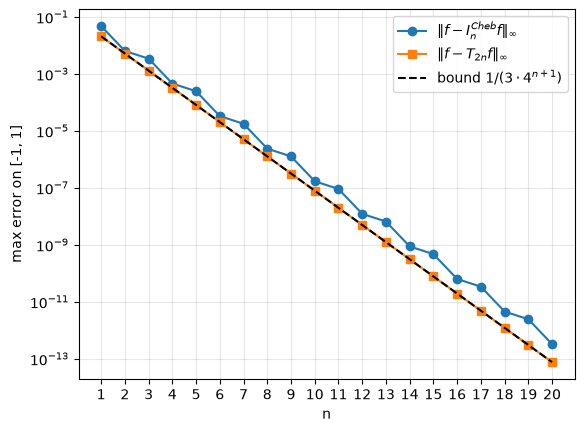

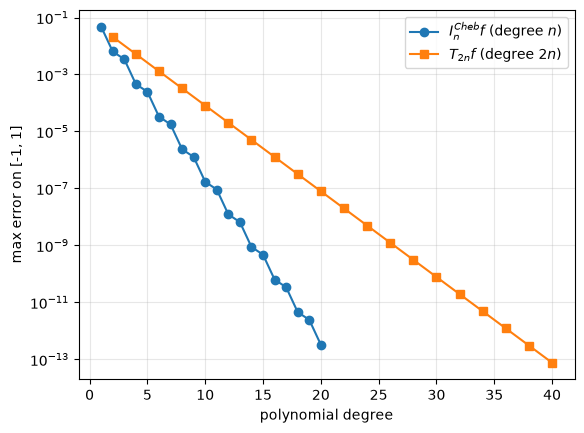

In [13]:
f = lambda x: 1.0 / (4.0 - x**2)

# Chebyshev points on [-1, 1], Theorem 1.21: n+1 points for degree n
def cheb_points(n):
    i = np.arange(n + 1)
    return np.cos(np.pi * (2 * i + 1) / (2 * n + 2))

# Taylor polynomial T_{2n} about 0: sum_{k=0}^{n} x^(2k) / 4^(k+1)
def taylor(x, n):
    k = np.arange(n + 1)
    return np.sum(x[:, None]**(2 * k) / 4.0**(k + 1), axis=1)

ns = np.arange(1, 21)
xe = np.linspace(-1, 1, 100)          # 100 uniform evaluation points

err_cheb, err_taylor = [], []
for n in ns:
    xc = cheb_points(n)
    p = np.array([N(f(xc), xc, t)[0, -1] for t in xe])
    err_cheb.append(np.max(np.abs(f(xe) - p)))
    err_taylor.append(np.max(np.abs(f(xe) - taylor(xe, n))))

# Plot 1: as required (x-axis = n)
plt.figure()
plt.semilogy(ns, err_cheb, "o-", label=r"$\|f - I_n^{Cheb} f\|_\infty$")
plt.semilogy(ns, err_taylor, "s-", label=r"$\|f - T_{2n} f\|_\infty$")
plt.semilogy(ns, 1 / (3 * 4.0**(ns + 1)), "k--", label=r"bound $1/(3\cdot 4^{n+1})$")
plt.xlabel("n"); plt.ylabel("max error on [-1, 1]")
plt.xticks(ns); plt.grid(True, which="both", alpha=0.3); plt.legend()

# Plot 2: same data vs. actual polynomial degree
plt.figure()
plt.semilogy(ns, err_cheb, "o-", label=r"$I_n^{Cheb} f$ (degree $n$)")
plt.semilogy(2 * ns, err_taylor, "s-", label=r"$T_{2n} f$ (degree $2n$)")
plt.xlabel("polynomial degree"); plt.ylabel("max error on [-1, 1]")
plt.grid(True, which="both", alpha=0.3); plt.legend()
plt.show()

At equal degree (as can be seen in the 2nd plot where the x axis is scaled accordingly), Chebyshev wins! At degree 10, for example, Chebyshev (n = 10) gives about 10^-7, while Taylor T_10 (n = 5 in the first plot) gives about 10^-5.

## 2.5 Harmonic Series

In [14]:
def S(N, chunksize=10**7) -> float:
    total = 0
    # We have to chunk as loading e.g. n = np.arange(1,10**9) will just overload the memory..
    for start in range(1, N+1, chunksize):
        stop = min(start+chunksize, N+1)
        n = np.arange(start, stop)
        total += np.sum(1/n)

    return total

In [15]:
for n in (10, 100, 1000):
    print(f"N={n}, S =", S(n))

N=10, S = 2.9289682539682538
N=100, S = 5.187377517639621
N=1000, S = 7.485470860550345


In [16]:
A = np.array([[1, 10**-1, 10**-2], [1, 100**-1, 100**-2], [1, 1000**-1, 1000**-2]])
b = np.array([S(10) - np.log(10), S(100) - np.log(100), S(1000) - np.log(1000)])

coeffs = np.linalg.solve(A, b)
print(coeffs)

a0, a1, a2 = coeffs

[ 0.57721567  0.49999899 -0.08324035]


In [17]:
def S_appr(N, a0, a1, a2):
    return np.log(N) + a0 + a1/N + a2/N

In [18]:
import time

start = time.time()
S_106 = S(10**6)
end = time.time()
print(end - start, "sec")

start = time.time()
S_106_appr = S_appr(10**6 , a0, a1, a2)
end = time.time()
print(end - start, "sec")

start = time.time()
S_108 = S(10**8)
end = time.time()
print(end - start, "sec")

start = time.time()
S_108_appr = S_appr(10**8 , a0, a1, a2)
end = time.time()
print(end - start, "sec")


print("error for 10**6: ", np.abs(S_106_appr - S_106))
print("error for 10**8: ", np.abs(S_108_appr - S_108))

0.0069997310638427734 sec
0.0001327991485595703 sec
0.692816972732544 sec
0.00015497207641601562 sec
error for 10**6:  8.232069070857051e-08
error for 10**8:  8.818190622150723e-11


In [19]:
for n in (10**8, 10**9):
    start = time.time()
    S_test = S(n)
    end = time.time()
    print(end - start, "sec for", n)

0.5179641246795654 sec for 100000000
3.390587329864502 sec for 1000000000
